In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
df=df.drop_duplicates()

In [9]:
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
cancelled.sum()
df = df[~cancelled]

In [10]:
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]

In [11]:
customer_df = df.dropna(subset=["CustomerID"]).copy()

In [12]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df[["Quantity", "UnitPrice", "Revenue"]].head()
df["Revenue"].describe()

count    524878.000000
mean         20.275399
std         271.693566
min           0.001000
25%           3.900000
50%           9.920000
75%          17.700000
max      168469.600000
Name: Revenue, dtype: float64

In [13]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Duplicates:", df.duplicated().sum())
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Invalid prices:", (df["UnitPrice"] <= 0).sum())

Rows: 524878
Columns: 9
Duplicates: 0
Negative quantities: 0
Invalid prices: 0


In [14]:
total_revenue = df["Revenue"].sum()
print("Total Revenue:", total_revenue)

total_orders = df["InvoiceNo"].nunique()
print(f"Total Orders: {total_orders:,}")

Total Revenue: 10642110.804000001
Total Orders: 19,960


In [15]:
aov = total_revenue / total_orders
print(f"Average Order Value: £ {aov:,.2f}")

total_items = df["Quantity"].sum()
print(f"Total Items Sold: {total_items:,}")

customer_df = df.dropna(subset=['CustomerID']).copy()
total_customers = customer_df["CustomerID"].nunique()
print(f"Total Customers: {total_customers:,}")

Average Order Value: £ 533.17
Total Items Sold: 5,572,420
Total Customers: 4,338


In [16]:
kpis = {
    "Total Revenue": total_revenue,
    "Total Orders": total_orders,
    "Total Customers": total_customers,
    "Average Order Value": aov,
    "Total Items Sold": total_items
}

kpis

{'Total Revenue': np.float64(10642110.804000001),
 'Total Orders': 19960,
 'Total Customers': 4338,
 'Average Order Value': np.float64(533.171883967936),
 'Total Items Sold': np.int64(5572420)}

In [17]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Month"] = df["InvoiceDate"].dt.to_period("M")
df[["InvoiceDate", "Month"]].head()

monthly_revenue = df.groupby("Month")["Revenue"].sum()
monthly_revenue.sort_values(ascending=False).head(5)

Month
2011-11    1503866.780
2011-10    1151263.730
2011-09    1056435.192
2010-12     821452.730
2011-05     769296.610
Freq: M, Name: Revenue, dtype: float64

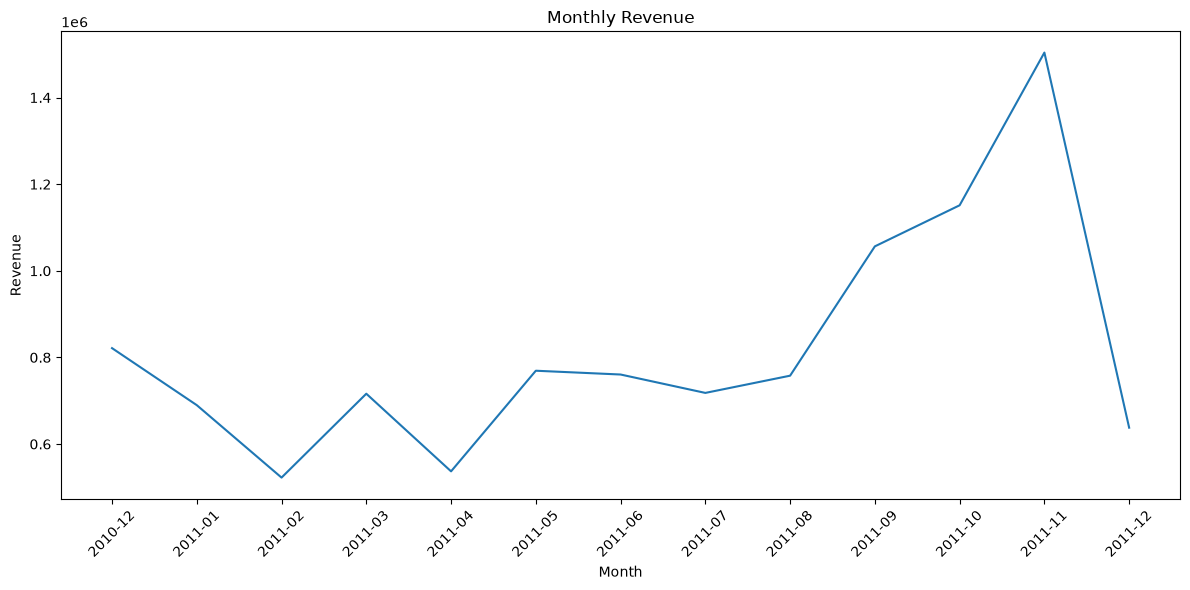

In [18]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values)
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

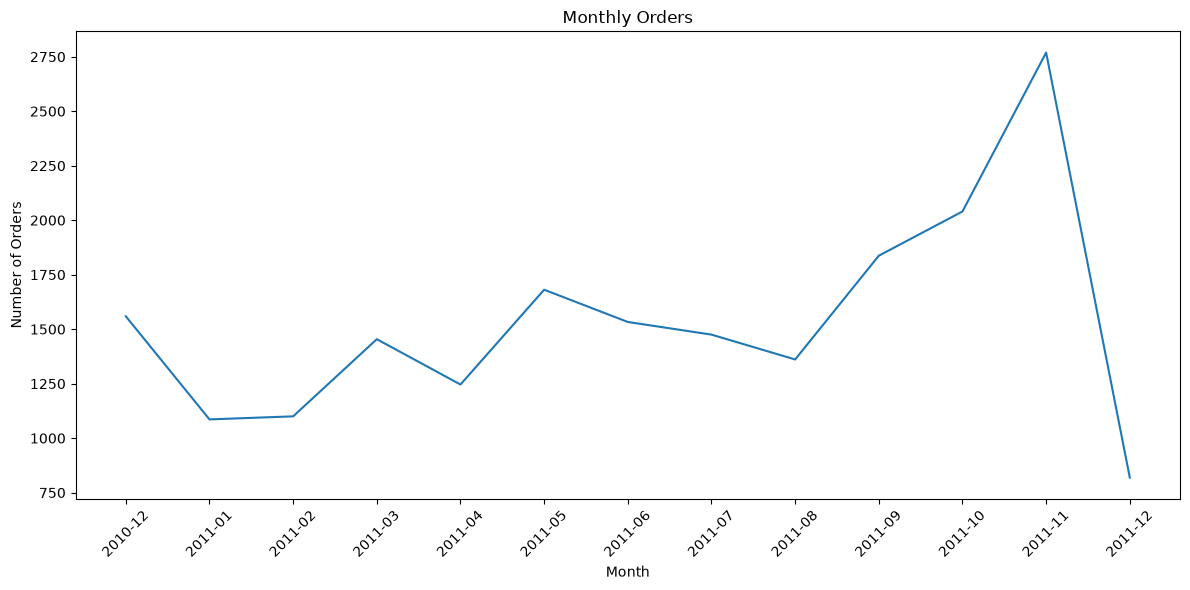

In [19]:
monthly_revenue = df.groupby("Month")["Revenue"].sum()
monthly_orders = df.groupby("Month")["InvoiceNo"].nunique()
monthly_aov = monthly_revenue / monthly_orders

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_orders.index.astype(str),
    monthly_orders.values
)

plt.title("Monthly Orders")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [20]:
monthly_analysis = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Orders": monthly_orders,
    "AOV": monthly_aov
})

monthly_analysis
monthly_analysis.sort_values("Revenue", ascending=False).head(10)
monthly_analysis.sort_values("Orders", ascending=False).head(10)

,Revenue,Orders,AOV
Month,,,
2011-11,1503866.780,2769,543.108263
2011-10,1151263.730,2040,564.344966
2011-09,1056435.192,1837,575.087203
2011-05,769296.610,1681,457.642243
2010-12,821452.730,1559,526.910026
2011-06,760547.010,1533,496.116771
2011-07,718076.121,1475,486.831268
2011-03,716215.260,1454,492.582710
2011-08,757841.380,1361,556.826877


In [22]:
df["StockCode"].nunique()
df["Description"].nunique()

4026

In [24]:
product_revenue = (
    df.groupby("Description")["Revenue"].sum().sort_values(ascending=False) 
)
product_revenue.head(10)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

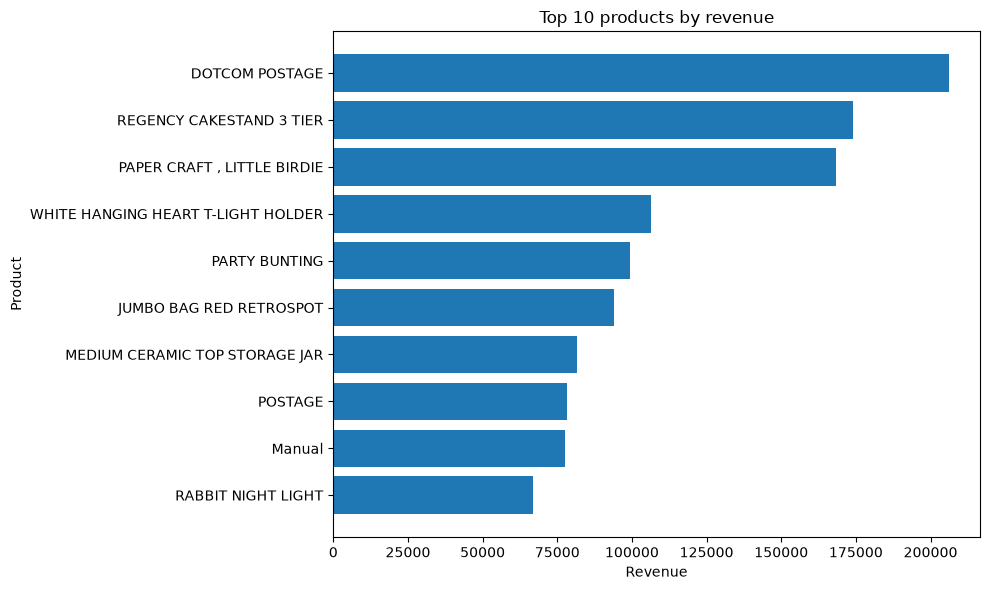

In [25]:
top_products = product_revenue.head(10).sort_values()
plt.figure(figsize=(10, 6))
plt.barh(top_products.index, top_products.values)
plt.title("Top 10 products by revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [26]:
product_quantity = (
    df.groupby("Description")["Quantity"].sum().sort_values(ascending=False)
)
product_quantity.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

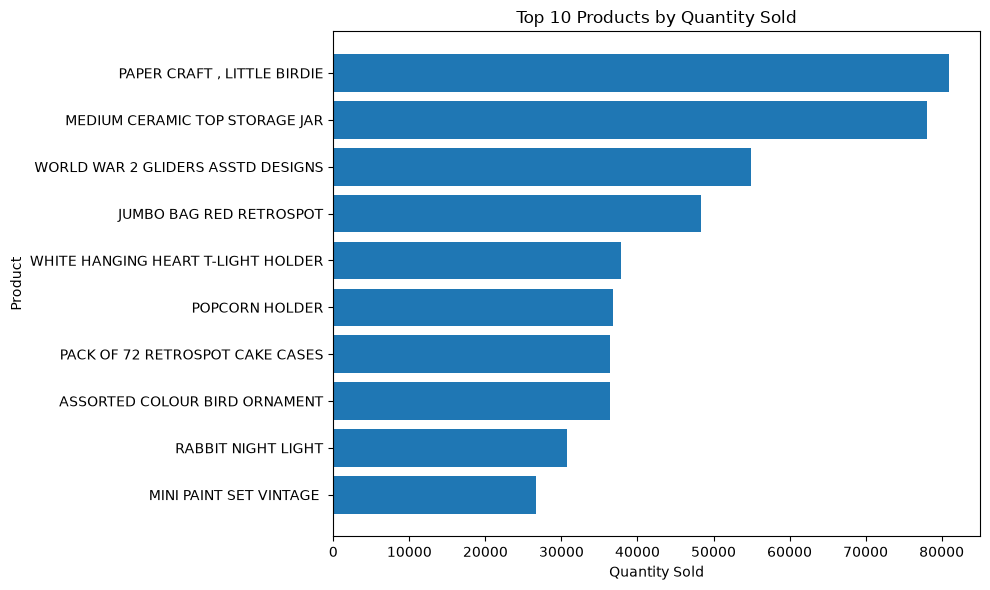

In [28]:
top_quantity = (
    product_quantity.head(10).sort_values()
)

plt.figure(figsize=(10,6))
plt.barh(top_quantity.index, top_quantity.values)
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [30]:
product_analysis = df.groupby("Description").agg(
    Revenue=("Revenue", "sum"),
    Quantity=("Quantity","sum"),
    Average_Unit_Price=("UnitPrice", "mean"),
    Orders=("InvoiceNo", "nunique")
)

product_analysis = product_analysis.sort_values(
    "Revenue",
    ascending=False
)

product_analysis.head(10)

,Revenue,Quantity,Average_Unit_Price,Orders
Description,,,,
DOTCOM POSTAGE,206248.77,706,292.137068,706
REGENCY CAKESTAND 3 TIER,174156.54,13851,13.983936,1988
"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,2.080000,1
WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,3.218334,2256
PARTY BUNTING,99445.23,18283,5.797928,1685
JUMBO BAG RED RETROSPOT,94159.81,48371,2.486197,2089
MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,1.468480,247
POSTAGE,78101.88,3150,31.076581,1126
Manual,77752.82,6985,233.757981,290


In [32]:
df["Description"].value_counts().head(20)
df["Description"].nunique()

4026

In [33]:
country_revenue = (
    df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
)
country_revenue.head(10)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

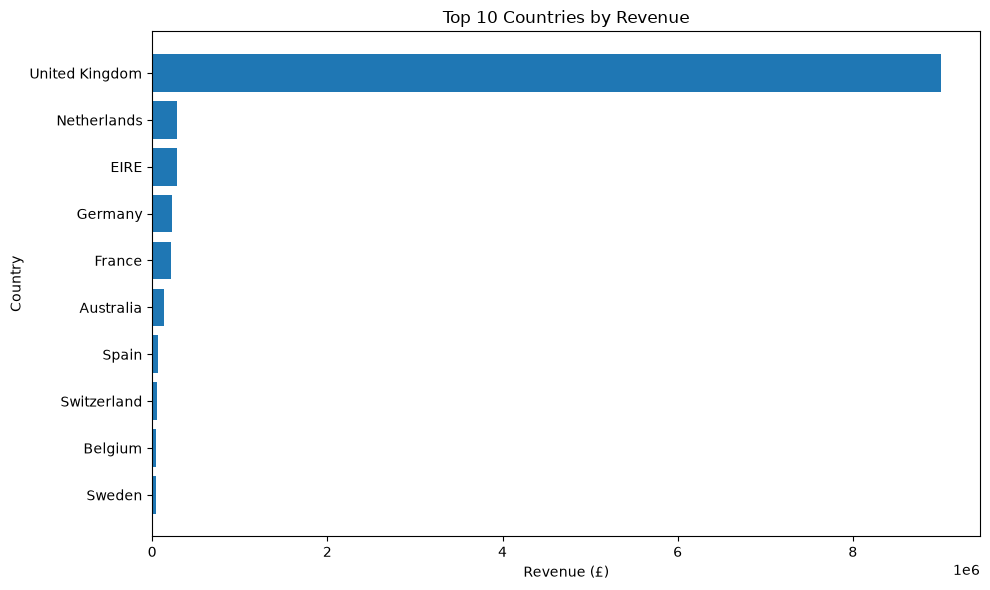

In [34]:
top_countries = country_revenue.head(10).sort_values()
plt.figure(figsize=(10,6))
plt.barh(top_countries.index, top_countries.values)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [37]:
country_analysis = df.groupby("Country").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Customers=("CustomerID","nunique")
)

country_analysis["AOV"] = (
    country_analysis["Revenue"] /
    country_analysis["Orders"]
)

country_analysis = country_analysis.sort_values(
    "Revenue",
    ascending=False
)

country_reliable = country_analysis[
    country_analysis["Orders"] >= 50
].sort_values("AOV", ascending=False)

country_reliable

,Revenue,Orders,Customers,AOV
Country,,,,
Netherlands,285446.340,94,9,3036.663191
Australia,138453.810,57,9,2429.014211
Switzerland,57067.600,54,21,1056.807407
EIRE,283140.520,288,3,983.126806
Spain,61558.560,90,30,683.984000
Portugal,33683.050,58,19,580.742241
France,209625.370,392,87,534.758597
Germany,228678.400,457,94,500.390372
United Kingdom,9001744.094,18019,3920,499.569571


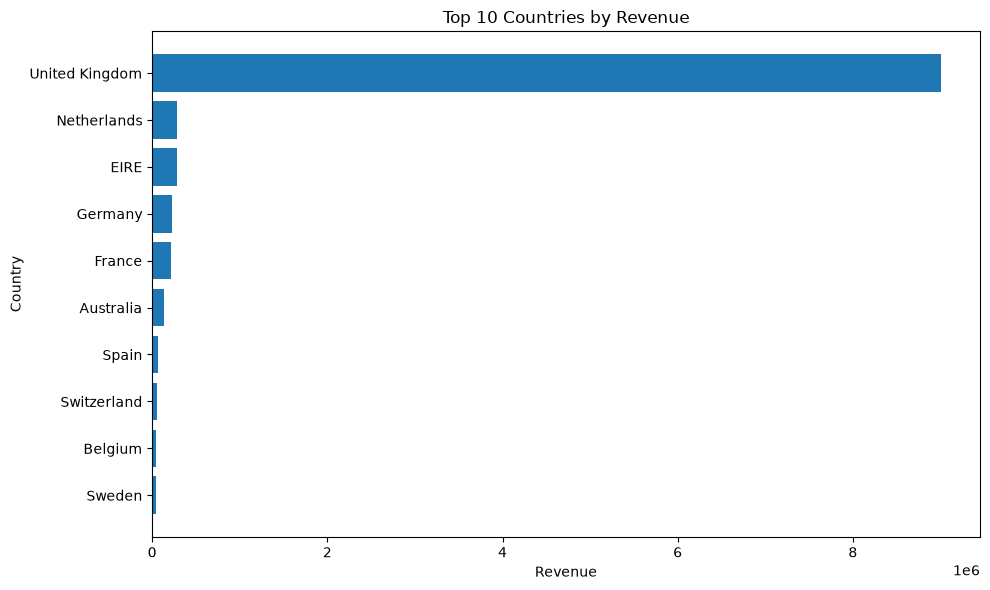

In [38]:
top_countries=(
    country_analysis.head(10).sort_values("Revenue")
)
plt.figure(figsize=(10, 6))
plt.barh(
    top_countries.index,
    top_countries["Revenue"]
)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [41]:
customer_df = df.dropna(subset=["CustomerID"]).copy()

customer_analysis = customer_df.groupby("CustomerID").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Items=("Quantity", "sum"),
    Average_Unit_Price=("UnitPrice", "mean")
)
customer_analysis.head()
customer_analysis.shape
customer_analysis.sort_values(
    "Revenue",
    ascending=False
).head(10)

,Revenue,Orders,Items,Average_Unit_Price
CustomerID,,,,
14646.0,280206.02,73,196915,2.493300
18102.0,259657.30,60,64124,4.503295
17450.0,194390.79,46,69973,3.378929
16446.0,168472.50,2,80997,1.660000
14911.0,143711.17,201,80240,4.612055
12415.0,124914.53,21,77374,2.937087
14156.0,117210.08,55,57768,3.834215
17511.0,91062.38,31,64549,2.306625
16029.0,80850.84,63,40108,36.185270


In [42]:
top_10_revenue = customer_analysis.nlargest(
    10, "Revenue"
)["Revenue"].sum()

top_10_share = top_10_revenue / df["Revenue"].sum() * 100

print(f"Top 10 customers generate {top_10_share:.2f}% of total revenue")

Top 10 customers generate 14.45% of total revenue


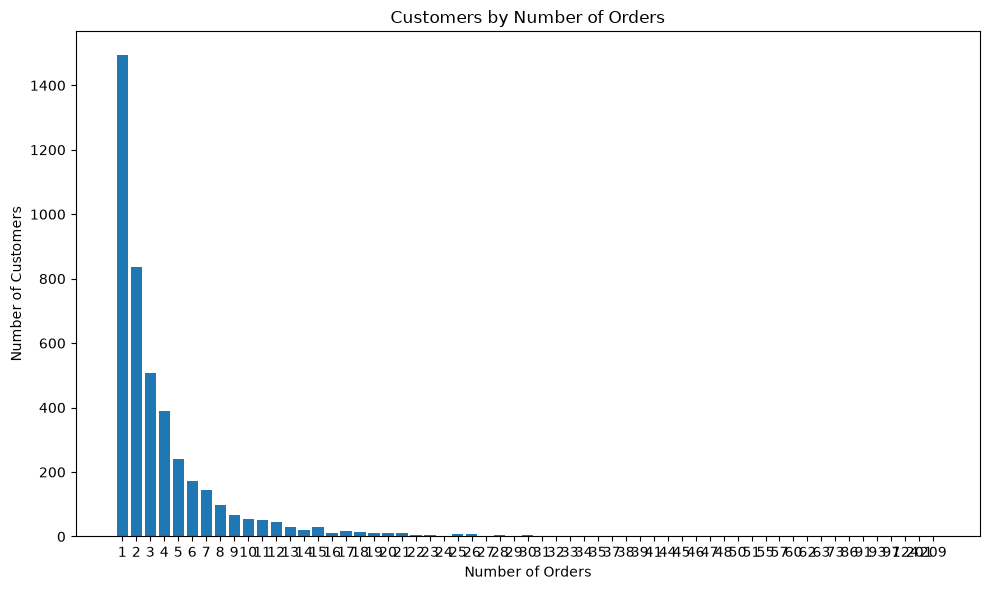

In [44]:
order_frequency = customer_analysis["Orders"].value_counts().sort_index()
order_frequency.head(20)
plt.figure(figsize=(10, 6))

plt.bar(
    order_frequency.index.astype(str),
    order_frequency.values
)

plt.title("Customers by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [45]:
customer_segments = pd.cut(
    customer_analysis["Orders"],
    bins=[0, 1, 3, 10, float("inf")],
    labels=["1 order", "2-3 orders", "4-10 orders", "10+ orders"]
)

customer_segments.value_counts().sort_index()

Orders
1 order        1493
2-3 orders     1343
4-10 orders    1165
10+ orders      337
Name: count, dtype: int64

In [47]:
df["InvoiceDate"].max()
analysis_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
analysis_date

recency = customer_df.groupby("CustomerID")["InvoiceDate"].max()
recency = (analysis_date - recency).dt.days
recency.head()

CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
Name: InvoiceDate, dtype: int64

In [48]:
frequency = customer_df.groupby("CustomerID")["InvoiceNo"].nunique()
frequency.head()

CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
Name: InvoiceNo, dtype: int64

In [49]:
monetary = customer_df.groupby("CustomerID")["Revenue"].sum()
monetary.head()

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
Name: Revenue, dtype: float64

In [53]:
rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


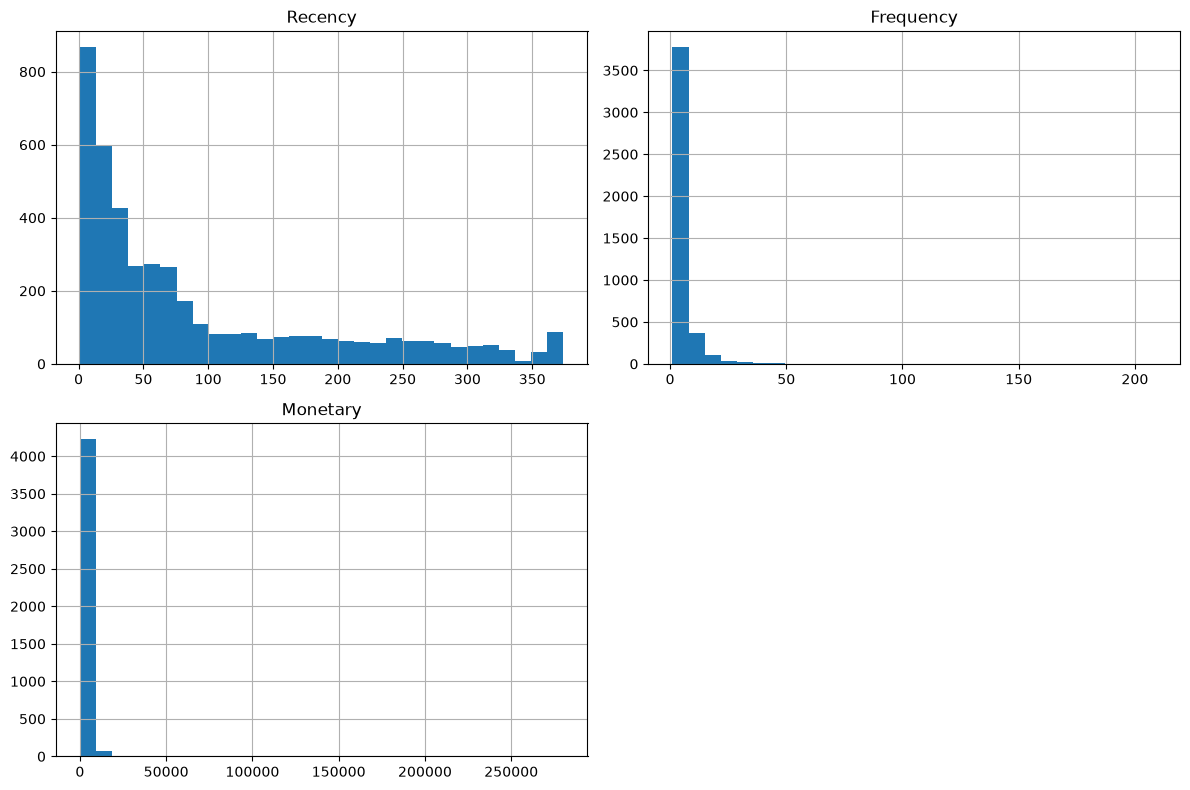

In [54]:
rfm.hist(figsize=(12, 8), bins=30)

plt.tight_layout()
plt.show()

In [55]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [57]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
)
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,326,1,77183.60,1,1,5
12347.0,2,7,4310.00,5,5,5
12348.0,75,4,1797.24,2,4,4
12349.0,19,1,1757.55,4,1,4
12350.0,310,1,334.40,1,1,2


In [59]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int) +
    rfm["F_Score"].astype(int) +
    rfm["M_Score"].astype(int)
)
rfm["RFM_Score"].value_counts().sort_index()

RFM_Score
3     183
4     361
5     337
6     426
7     377
8     375
9     336
10    342
11    347
12    321
13    286
14    300
15    347
Name: count, dtype: int64

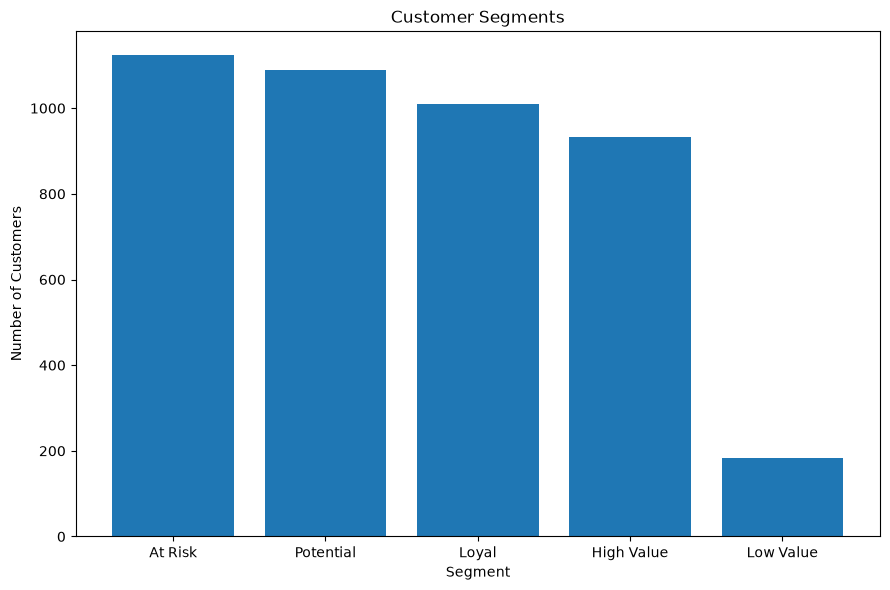

In [60]:
def segment_customer(score):
    if score >= 13:
        return "High Value"
    elif score >= 10:
        return "Loyal"
    elif score >= 7:
        return "Potential"
    elif score >= 4:
        return "At Risk"
    else:
        return "Low Value"

rfm["Segment"] = rfm["RFM_Score"].apply(segment_customer)
rfm["Segment"].value_counts()
segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(9, 6))

plt.bar(
    segment_counts.index,
    segment_counts.values
)

plt.title("Customer Segments")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [61]:
rfm.sort_values(
    ["RFM_Score", "Monetary"],
    ascending=[False, False]
).head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
14646.0,2,73,280206.02,5,5,5,15,High Value
18102.0,1,60,259657.30,5,5,5,15,High Value
17450.0,8,46,194390.79,5,5,5,15,High Value
14911.0,1,201,143711.17,5,5,5,15,High Value
14156.0,10,55,117210.08,5,5,5,15,High Value
17511.0,3,31,91062.38,5,5,5,15,High Value
16684.0,4,28,66653.56,5,5,5,15,High Value
14096.0,4,17,65164.79,5,5,5,15,High Value
13694.0,4,50,65039.62,5,5,5,15,High Value


In [62]:
rfm.groupby("Segment")["Monetary"].agg(
    ["count", "mean", "median", "sum"]
).sort_values("sum", ascending=False)

,count,mean,median,sum
Segment,,,,
High Value,933,6689.759668,3000.200,6241545.770
Loyal,1010,1389.110526,1084.865,1403001.631
Potential,1088,807.018118,531.560,878035.712
At Risk,1124,300.904663,257.975,338216.841
Low Value,183,144.311148,141.410,26408.940


In [63]:
customer_revenue = (
    customer_analysis["Revenue"]
    .sort_values(ascending=False)
)

total_customer_revenue = customer_revenue.sum()

for n in [1, 5, 10, 50, 100]:
    share = customer_revenue.head(n).sum() / total_customer_revenue * 100
    print(f"Top {n} customers: {share:.2f}% of revenue")

Top 1 customers: 3.15% of revenue
Top 5 customers: 11.77% of revenue
Top 10 customers: 17.30% of revenue
Top 50 customers: 33.30% of revenue
Top 100 customers: 40.61% of revenue


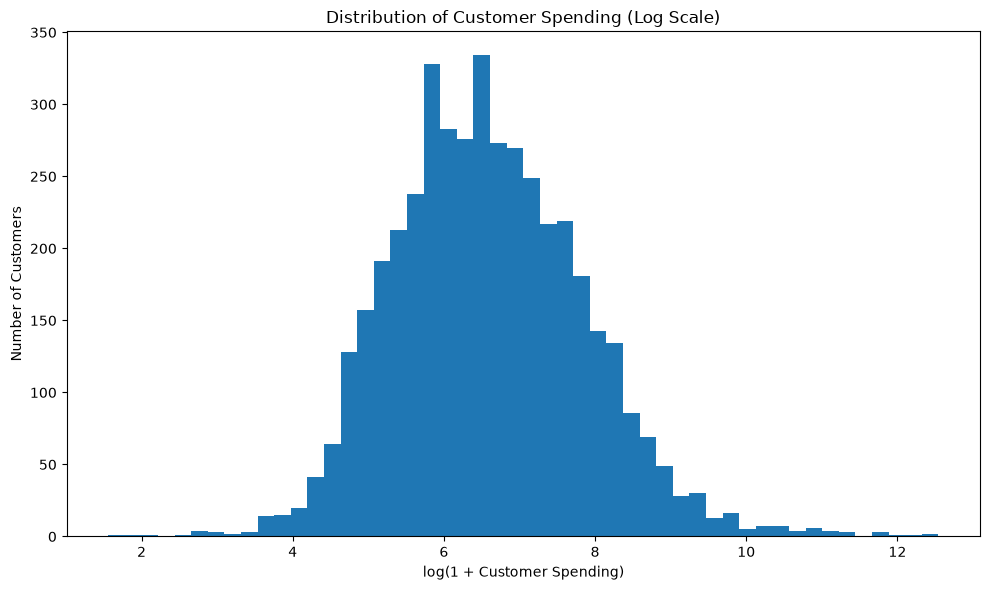

In [65]:
plt.figure(figsize=(10, 6))

plt.hist(
    np.log1p(rfm["Monetary"]),
    bins=50
)

plt.title("Distribution of Customer Spending (Log Scale)")
plt.xlabel("log(1 + Customer Spending)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

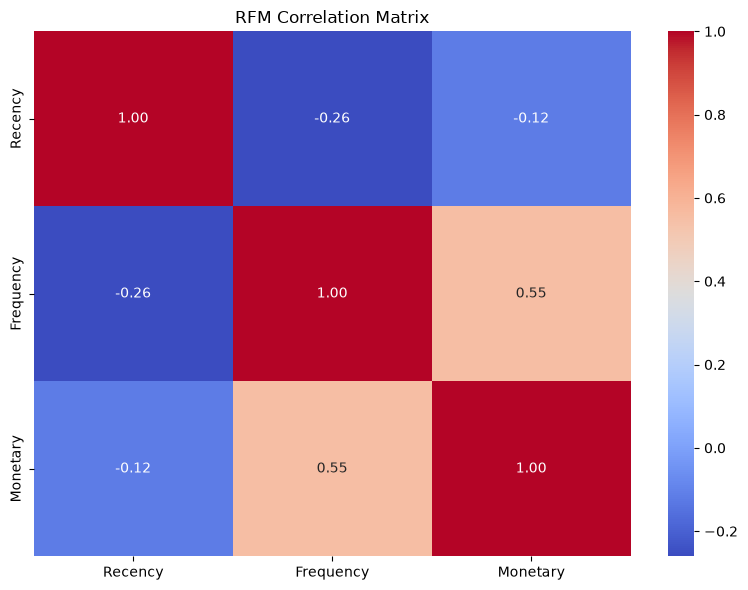

In [67]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    rfm[["Recency", "Frequency", "Monetary"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("RFM Correlation Matrix")

plt.tight_layout()
plt.show()

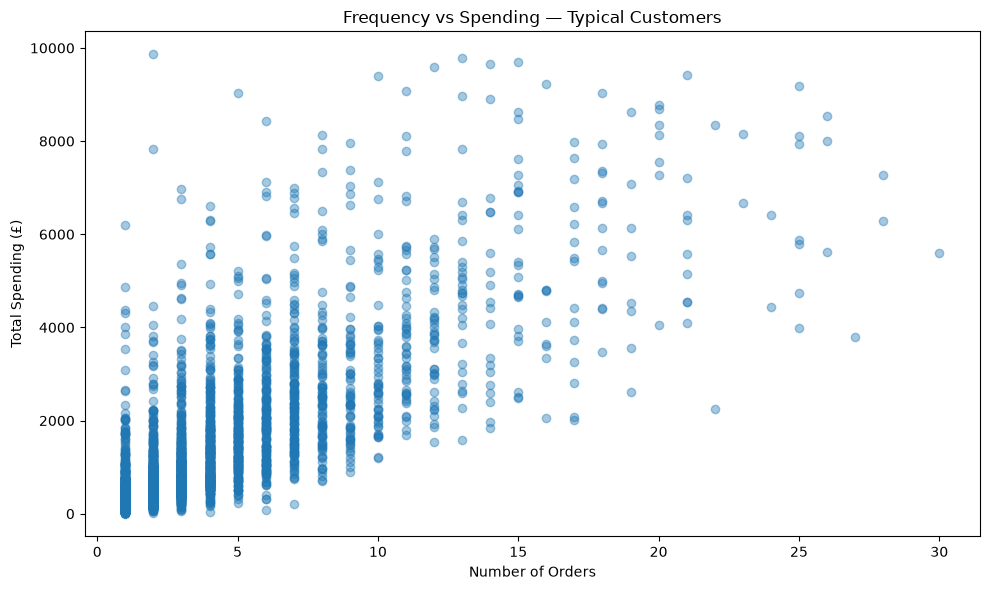

In [69]:
plot_data = rfm[
    (rfm["Frequency"] <= 30) &
    (rfm["Monetary"] <= 10000)
]

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["Frequency"],
    plot_data["Monetary"],
    alpha=0.4
)

plt.title("Frequency vs Spending — Typical Customers")
plt.xlabel("Number of Orders")
plt.ylabel("Total Spending (£)")

plt.tight_layout()
plt.show()